In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [3]:
data = pd.read_csv("dataset.csv")
data.head(10)
print(data.columns)

Index(['invoice_id', 'date_time', 'branch', 'customer_type', 'gender',
       'category', 'product', 'unit_price', 'quantity', 'subtotal', 'tax_5pct',
       'total_amount', 'payment_method'],
      dtype='str')


In [ ]:

most_sale_product = data.groupby("product")['quantity'].sum()
print(f"most sale product : {most_sale_product.idxmax()}")

data["revenue"] = data["unit_price"] * data["subtotal"]
catagory_revenue = data.groupby("category")["revenue"].sum()
print(f"Category : {catagory_revenue.idxmax()} Revenue : {catagory_revenue.max()}")
avg_bill = data["subtotal"].mean()
print("Average Bill : ",avg_bill)

data["date_time"] = pd.to_datetime(data["date_time"])
data["day_name"] = data["date_time"].dt.strftime("%A")
highest_sale_day = data.groupby("day_name")["revenue"].sum()
print(f"Day :{highest_sale_day.idxmax()} Revenue:{highest_sale_day.max()}")

top_customers =( data.groupby("customer_type")["revenue"]
                .sum()
                .sort_values(ascending=False)
            )
print(top_customers.idxmax(), top_customers.max())

# how do male/female customers differ in purchasing?
gender_analysis = (
    data.groupby("gender").agg(
        total_revenue= ("revenue", "sum"),
        avg_spending_per_transaction = ("revenue", "mean"),
        total_transaction = ("invoice_id", "nunique"),
        avg_unit_per_order = ("quantity", "mean")
    ).reset_index()
)

display(gender_analysis)


data.head()

most sale product : Sugar (1kg)
Category : Groceries & Staples Revenue : 172136000
Average Bill :  1639.4
Day :Friday Revenue:70578200
Member 137543300


,gender,total_revenue,avg_spending_per_transaction,total_transaction,avg_unit_per_order
0,Female,107643100,1.045079e+06,103,4.932039
1,Male,119593500,1.232923e+06,97,4.855670


,invoice_id,date_time,branch,customer_type,gender,category,product,unit_price,quantity,subtotal,tax_5pct,total_amount,payment_method,revenue,day_name
0,INV-2026-1001,2026-01-01 00:00:00,Rawalpindi - Saddar,Normal,Female,Dairy & Bakery,Cheddar Cheese (200g),650,9,5850,292.5,6142.5,Cash,3802500,Thursday
1,INV-2026-1002,2026-01-02 05:11:00,Peshawar - Cantt,Normal,Female,Personal Care & Cleaning,Tissues Box,220,3,660,33.0,693.0,Cash,145200,Friday
2,INV-2026-1003,2026-01-03 10:22:00,Lahore - Gulberg,Normal,Male,Produce,Onions (1kg),120,2,240,12.0,252.0,Debit Card,28800,Saturday
3,INV-2026-1004,2026-01-04 15:33:00,Islamabad - F-7,Member,Female,Snacks & Beverages,Potato Chips,100,2,200,10.0,210.0,Credit Card,20000,Sunday
4,INV-2026-1005,2026-01-05 20:44:00,Karachi - DHA,Normal,Male,Personal Care & Cleaning,Hand Soap,120,7,840,42.0,882.0,Cash,100800,Monday


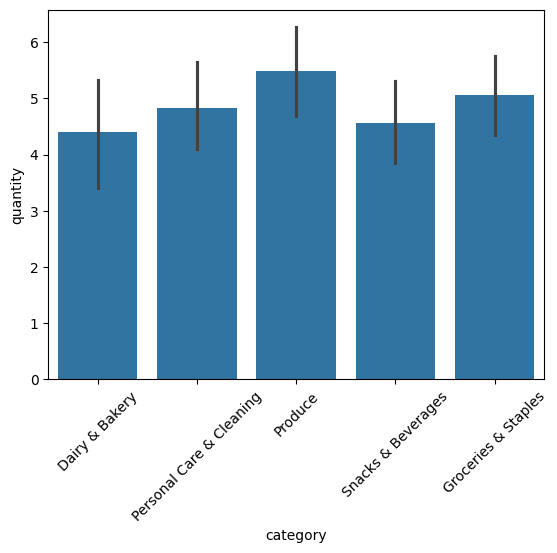

In [15]:
sns.barplot(data=data, x="category", y="quantity")
plt.xticks(rotation = 45)
plt.show()